<a href="https://colab.research.google.com/github/juttigaharshitha7/Student-Performance-Prediction-ML/blob/main/Student_Performance_Prediction_ML.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [18]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import os

In [19]:
from google.colab import files
uploaded = files.upload()

Saving StudentPerformanceFactors.csv to StudentPerformanceFactors (1).csv


In [20]:
file_name = next(iter(uploaded))
df = pd.read_csv(file_name)

In [21]:
print("Dataset uploaded successfully!")
display(df)
print("\nDataset shape:")
print(df.shape)

Dataset uploaded successfully!


,Hours_Studied,Attendance,Parental_Involvement,Access_to_Resources,Extracurricular_Activities,Sleep_Hours,Previous_Scores,Motivation_Level,Internet_Access,Tutoring_Sessions,Family_Income,Teacher_Quality,School_Type,Peer_Influence,Physical_Activity,Learning_Disabilities,Parental_Education_Level,Distance_from_Home,Gender,Exam_Score
0,23,84,Low,High,No,7,73,Low,Yes,0,Low,Medium,Public,Positive,3,No,High School,Near,Male,67
1,19,64,Low,Medium,No,8,59,Low,Yes,2,Medium,Medium,Public,Negative,4,No,College,Moderate,Female,61
2,24,98,Medium,Medium,Yes,7,91,Medium,Yes,2,Medium,Medium,Public,Neutral,4,No,Postgraduate,Near,Male,74
3,29,89,Low,Medium,Yes,8,98,Medium,Yes,1,Medium,Medium,Public,Negative,4,No,High School,Moderate,Male,71
4,19,92,Medium,Medium,Yes,6,65,Medium,Yes,3,Medium,High,Public,Neutral,4,No,College,Near,Female,70
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
6602,25,69,High,Medium,No,7,76,Medium,Yes,1,High,Medium,Public,Positive,2,No,High School,Near,Female,68
6603,23,76,High,Medium,No,8,81,Medium,Yes,3,Low,High,Public,Positive,2,No,High School,Near,Female,69
6604,20,90,Medium,Low,Yes,6,65,Low,Yes,3,Low,Medium,Public,Negative,2,No,Postgraduate,Near,Female,68
6605,10,86,High,High,Yes,6,91,High,Yes,2,Low,Medium,Private,Positive,3,No,High School,Far,Female,68



Dataset shape:
(6607, 20)


In [22]:
print("Dataset Columns:")
print(df.columns.tolist())
print("\nDataset Information:")
df.info()
print("\nMissing Values in Each Column:")
print(df.isnull().sum())
print("\nStatistical Summary:")
display(df.describe())

Dataset Columns:
['Hours_Studied', 'Attendance', 'Parental_Involvement', 'Access_to_Resources', 'Extracurricular_Activities', 'Sleep_Hours', 'Previous_Scores', 'Motivation_Level', 'Internet_Access', 'Tutoring_Sessions', 'Family_Income', 'Teacher_Quality', 'School_Type', 'Peer_Influence', 'Physical_Activity', 'Learning_Disabilities', 'Parental_Education_Level', 'Distance_from_Home', 'Gender', 'Exam_Score']

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6607 entries, 0 to 6606
Data columns (total 20 columns):
 #   Column                      Non-Null Count  Dtype 
---  ------                      --------------  ----- 
 0   Hours_Studied               6607 non-null   int64 
 1   Attendance                  6607 non-null   int64 
 2   Parental_Involvement        6607 non-null   object
 3   Access_to_Resources         6607 non-null   object
 4   Extracurricular_Activities  6607 non-null   object
 5   Sleep_Hours                 6607 non-null   int64 
 6   Previous_

,Hours_Studied,Attendance,Sleep_Hours,Previous_Scores,Tutoring_Sessions,Physical_Activity,Exam_Score
count,6607.000000,6607.000000,6607.00000,6607.000000,6607.000000,6607.000000,6607.000000
mean,19.975329,79.977448,7.02906,75.070531,1.493719,2.967610,67.235659
std,5.990594,11.547475,1.46812,14.399784,1.230570,1.031231,3.890456
min,1.000000,60.000000,4.00000,50.000000,0.000000,0.000000,55.000000
25%,16.000000,70.000000,6.00000,63.000000,1.000000,2.000000,65.000000
50%,20.000000,80.000000,7.00000,75.000000,1.000000,3.000000,67.000000
75%,24.000000,90.000000,8.00000,88.000000,2.000000,4.000000,69.000000
max,44.000000,100.000000,10.00000,100.000000,8.000000,6.000000,101.000000


In [23]:
duplicate_count = df.duplicated().sum()
print("Number of Duplicate Records:", duplicate_count)
df.drop_duplicates(inplace=True)
print("\nDuplicate Records After Cleaning:")
print(df.duplicated().sum())
print("\nDataset After Removing Duplicates:")
display(df)

Number of Duplicate Records: 0

Duplicate Records After Cleaning:
0

Dataset After Removing Duplicates:


,Hours_Studied,Attendance,Parental_Involvement,Access_to_Resources,Extracurricular_Activities,Sleep_Hours,Previous_Scores,Motivation_Level,Internet_Access,Tutoring_Sessions,Family_Income,Teacher_Quality,School_Type,Peer_Influence,Physical_Activity,Learning_Disabilities,Parental_Education_Level,Distance_from_Home,Gender,Exam_Score
0,23,84,Low,High,No,7,73,Low,Yes,0,Low,Medium,Public,Positive,3,No,High School,Near,Male,67
1,19,64,Low,Medium,No,8,59,Low,Yes,2,Medium,Medium,Public,Negative,4,No,College,Moderate,Female,61
2,24,98,Medium,Medium,Yes,7,91,Medium,Yes,2,Medium,Medium,Public,Neutral,4,No,Postgraduate,Near,Male,74
3,29,89,Low,Medium,Yes,8,98,Medium,Yes,1,Medium,Medium,Public,Negative,4,No,High School,Moderate,Male,71
4,19,92,Medium,Medium,Yes,6,65,Medium,Yes,3,Medium,High,Public,Neutral,4,No,College,Near,Female,70
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
6602,25,69,High,Medium,No,7,76,Medium,Yes,1,High,Medium,Public,Positive,2,No,High School,Near,Female,68
6603,23,76,High,Medium,No,8,81,Medium,Yes,3,Low,High,Public,Positive,2,No,High School,Near,Female,69
6604,20,90,Medium,Low,Yes,6,65,Low,Yes,3,Low,Medium,Public,Negative,2,No,Postgraduate,Near,Female,68
6605,10,86,High,High,Yes,6,91,High,Yes,2,Low,Medium,Private,Positive,3,No,High School,Far,Female,68


In [24]:
missing_values = df.isnull().sum()
print("Missing Values in Each Column:")
print(missing_values)
missing_percentage = (missing_values / len(df)) * 100
print("\nMissing Value Percentage:")
print(missing_percentage.round(2))
print("\nColumns Containing Missing Values:")
print(missing_values[missing_values > 0])

Missing Values in Each Column:
Hours_Studied                  0
Attendance                     0
Parental_Involvement           0
Access_to_Resources            0
Extracurricular_Activities     0
Sleep_Hours                    0
Previous_Scores                0
Motivation_Level               0
Internet_Access                0
Tutoring_Sessions              0
Family_Income                  0
Teacher_Quality               78
School_Type                    0
Peer_Influence                 0
Physical_Activity              0
Learning_Disabilities          0
Parental_Education_Level      90
Distance_from_Home            67
Gender                         0
Exam_Score                     0
dtype: int64

Missing Value Percentage:
Hours_Studied                 0.00
Attendance                    0.00
Parental_Involvement          0.00
Access_to_Resources           0.00
Extracurricular_Activities    0.00
Sleep_Hours                   0.00
Previous_Scores               0.00
Motivation_Level        

In [25]:
numerical_columns = df.select_dtypes(include=["number"]).columns
categorical_columns = df.select_dtypes(include=["object", "category"]).columns
for column in numerical_columns:
    df[column] = df[column].fillna(df[column].median())
for column in categorical_columns:
    if df[column].notna().any():
        df[column] = df[column].fillna(df[column].mode()[0])
print("Missing Values After Cleaning:")
print(df.isnull().sum())

Missing Values After Cleaning:
Hours_Studied                 0
Attendance                    0
Parental_Involvement          0
Access_to_Resources           0
Extracurricular_Activities    0
Sleep_Hours                   0
Previous_Scores               0
Motivation_Level              0
Internet_Access               0
Tutoring_Sessions             0
Family_Income                 0
Teacher_Quality               0
School_Type                   0
Peer_Influence                0
Physical_Activity             0
Learning_Disabilities         0
Parental_Education_Level      0
Distance_from_Home            0
Gender                        0
Exam_Score                    0
dtype: int64


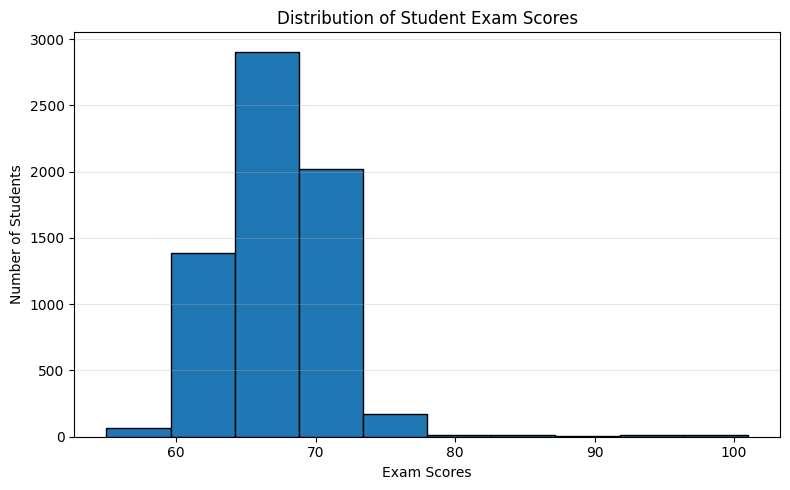

In [26]:
score_column = next(
    (col for col in df.columns
     if "exam" in col.lower() and "score" in col.lower()),
    None
)
if score_column is None:
    print("Exam score column not found.")
    print("Available columns:", df.columns.tolist())
else:
    plt.figure(figsize=(8, 5))

    plt.hist(
        df[score_column],
        bins=10,
        edgecolor="black"
    )
    plt.title("Distribution of Student Exam Scores")
    plt.xlabel("Exam Scores")
    plt.ylabel("Number of Students")
    plt.grid(axis="y", alpha=0.3)
    plt.tight_layout()
    plt.show()

In [27]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, r2_score

In [28]:
X = df[["Hours_Studied"]]
y = df["Exam_Score"]
print("Input Feature (X):")
display(X.head())
print("\nTarget Variable (y):")
display(y.head())

Input Feature (X):


,Hours_Studied
0,23
1,19
2,24
3,29
4,19



Target Variable (y):


,Exam_Score
0,67
1,61
2,74
3,71
4,70


In [29]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)
print("Training Records:", len(X_train))
print("Testing Records:", len(X_test))
print("\nDataset split completed successfully!")

Training Records: 5285
Testing Records: 1322

Dataset split completed successfully!


In [30]:
model = LinearRegression()
model.fit(X_train, y_train)
print("Linear Regression Model Trained Successfully!")

Linear Regression Model Trained Successfully!


In [31]:
y_pred = model.predict(X_test)
print("Predicted Exam Scores:")
print(y_pred[:5])
comparison = pd.DataFrame({
    "Actual Exam Score": y_test.values,
    "Predicted Exam Score": y_pred.round(2)
})
print("\nActual vs Predicted Scores:")
display(comparison.head(10))

Predicted Exam Scores:
[67.22454236 67.79587985 67.5102111  64.9391924  67.5102111 ]

Actual vs Predicted Scores:


,Actual Exam Score,Predicted Exam Score
0,65,67.22
1,65,67.80
2,71,67.51
3,64,64.94
4,66,67.51
5,66,67.51
6,72,72.08
7,66,68.37
8,70,66.37
9,70,66.08


In [17]:
hours = float(input("Enter the number of hours you study: "))
new_student = pd.DataFrame({
    X.columns[0]: [hours]
})
predicted_score = model.predict(new_student)
print("\nSTUDENT PERFORMANCE PREDICTION")
print("--------------------------------")
print("Study Hours:", hours)
print("Predicted Exam Score:", round(predicted_score[0], 2))

Enter the number of hours you study: 8

STUDENT PERFORMANCE PREDICTION
--------------------------------
Study Hours: 8.0
Predicted Exam Score: 63.8
